In [1]:
import pandas as pd
import numpy as np

In [2]:
housing = pd.read_csv("Housing (1).csv")

In [3]:
housing.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [4]:
housing.info()

<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 69.2 KB


In [5]:
housing.shape

(545, 13)

# Step1: Doing EDA using graphs
- 1.1 Pairplot or Scatterplot to check how the regression output variable is related to the rest of the variables.
- 1.2 Check the Multicollinearity
- 1.3 Visualize Categorical Variablle using Boxplots

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

<Axes: xlabel='price', ylabel='area'>

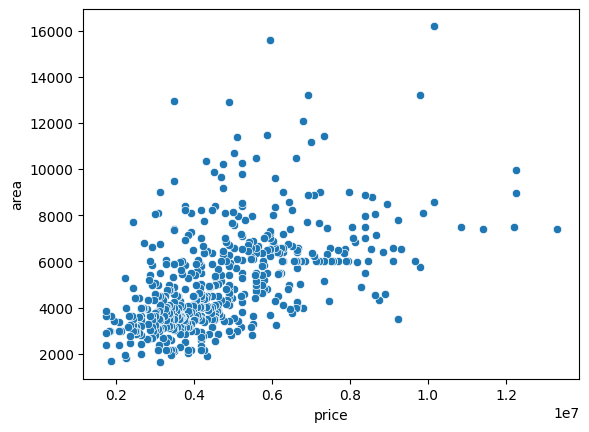

In [7]:
sns.scatterplot(data = housing, x='price', y='area')


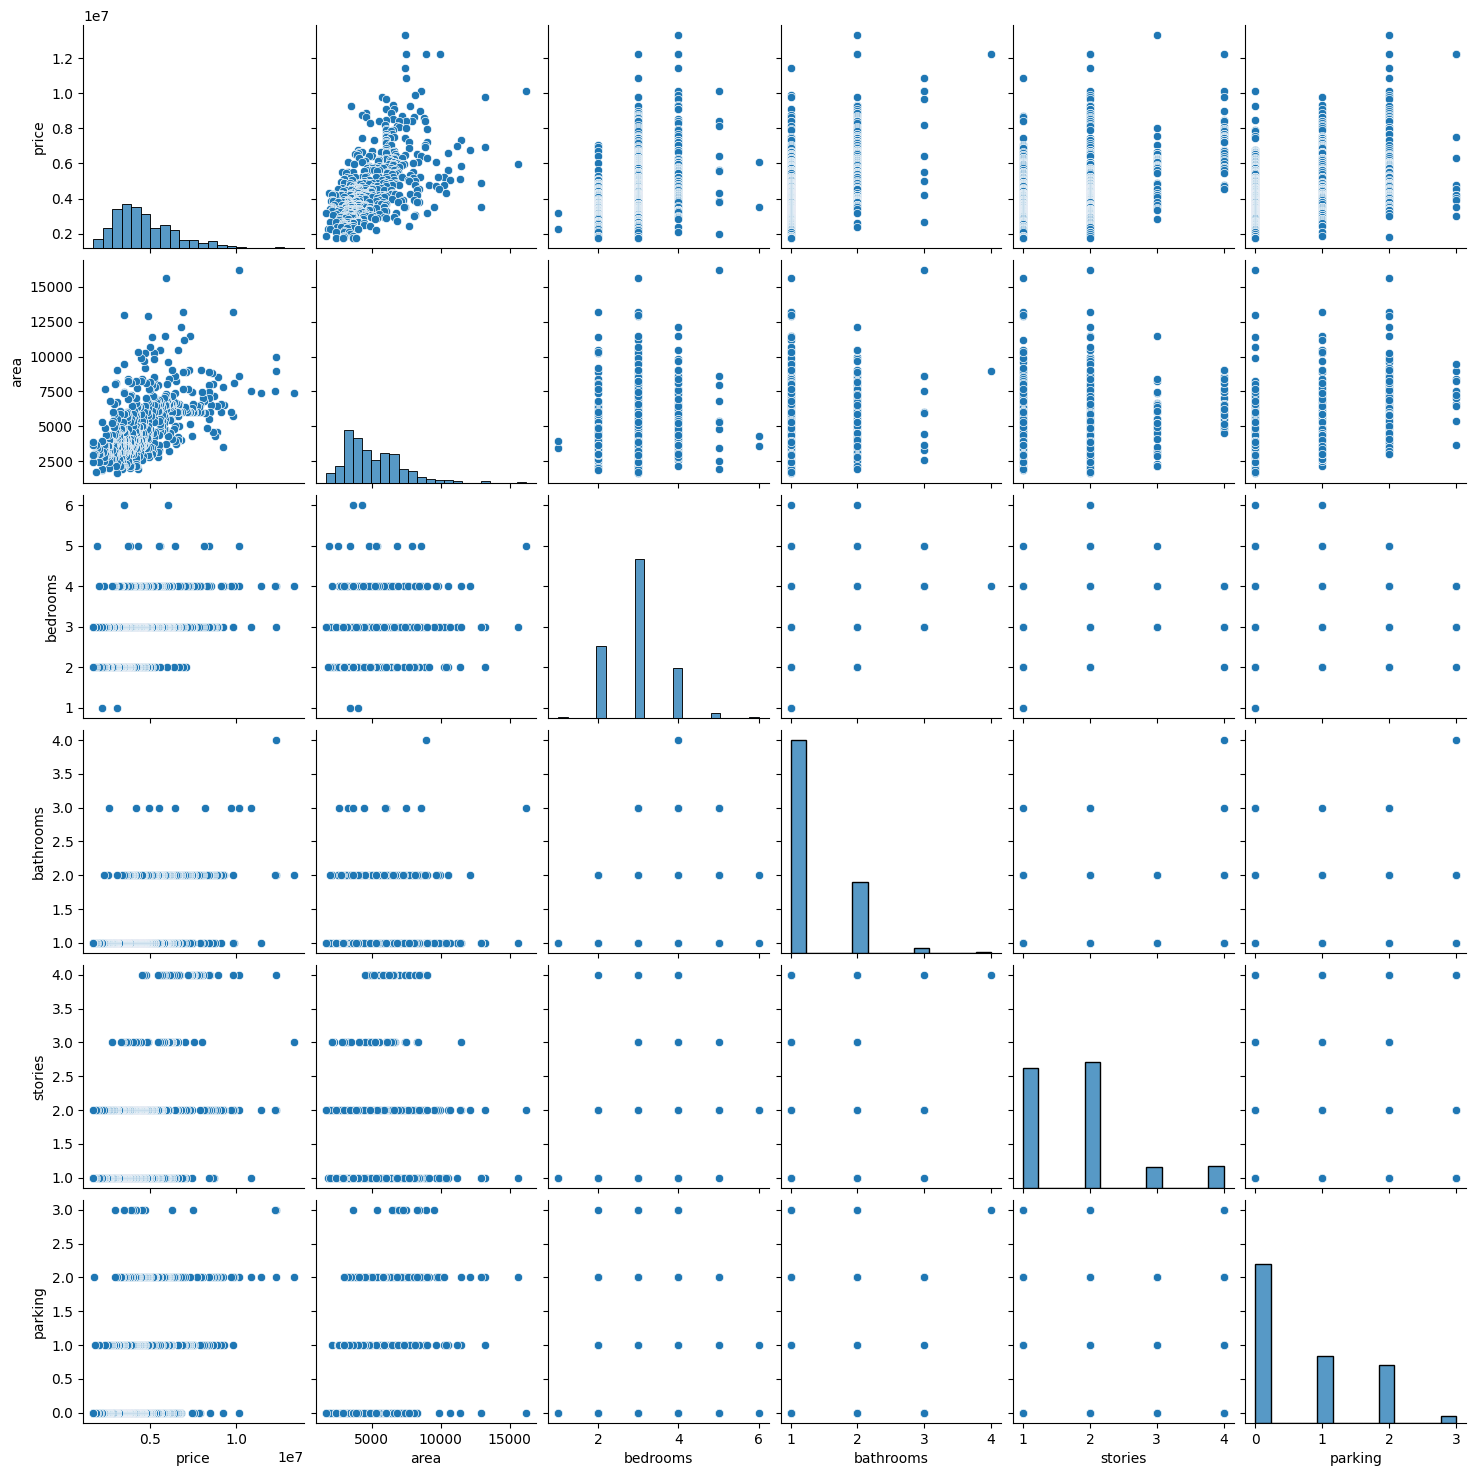

In [8]:
sns.pairplot(housing)

In [9]:
numerical_cols = ['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'parking']

In [10]:
# 1.2 Check the Multicollinearity
# For initial EDA, we check multicollinearity among the existing numerical features.

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Add a constant to the dataframe for VIF calculation
X = housing[numerical_cols].drop('price', axis=1) # Drop the target variable for VIF
X_const = add_constant(X)

vif_data = pd.DataFrame()
vif_data["feature"] = X_const.columns
vif_data["VIF"] = [variance_inflation_factor(X_const.values, i) for i in range(X_const.shape[1])]

print("\nVIF for numerical features:")
print(vif_data)
# Note: VIF values > 5 or 10 usually indicate high multicollinearity.


VIF for numerical features:
     feature        VIF
0      const  21.415032
1       area   1.170959
2   bedrooms   1.316597
3  bathrooms   1.252775
4    stories   1.255202
5    parking   1.164172


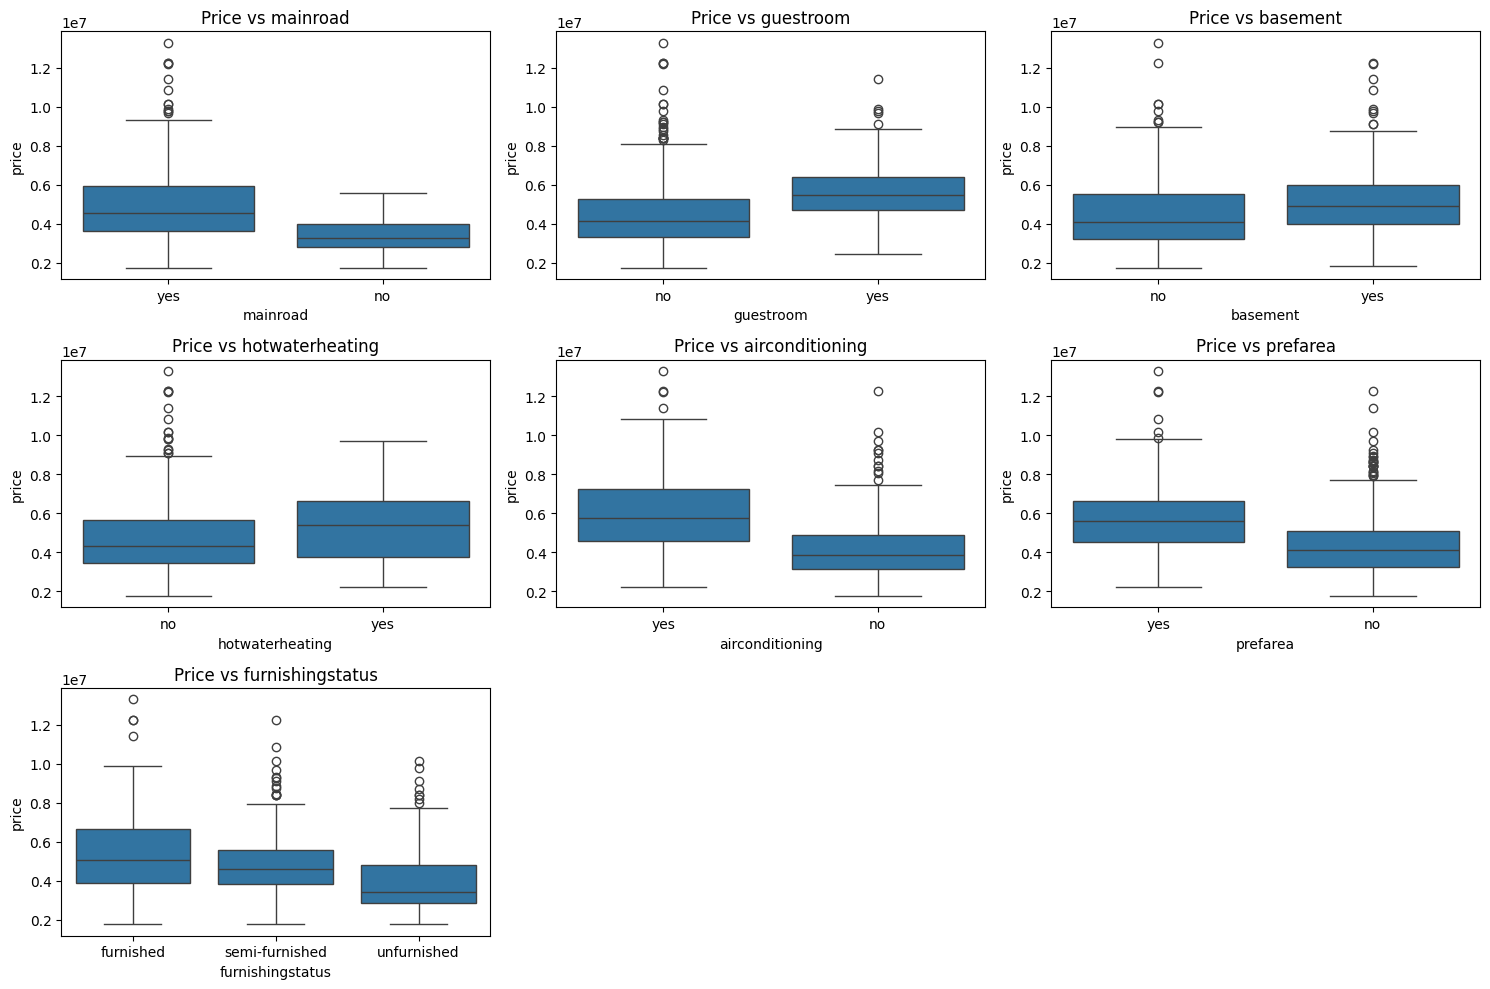

In [11]:
# 1.3 Visualize Categorical Variable using Boxplots
categorical_cols = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']

plt.figure(figsize=(15, 10))
for i, col in enumerate(categorical_cols):
    plt.subplot(3, 3, i + 1) # Arrange plots in a 3x3 grid
    sns.boxplot(x=col, y='price', data=housing)
    plt.title(f'Price vs {col}')
plt.tight_layout()
plt.show()

# Step2: Convert all non-numeric variables to numeric variables.
- 2.1 Using dummy variable convert the categorical variables to numerical.
- 2.2 Concatinating the dummy variables to original dataframe.

In [12]:
# List all variables to map
varlist = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']

# Defining the map function
def binary_map(x):
    return x.map({'yes': 1, "no": 0})

housing[varlist] = housing[varlist].apply(binary_map)

In [13]:
housing.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,furnished
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,furnished
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,semi-furnished
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,furnished
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,furnished


In [14]:
status = pd.get_dummies(housing['furnishingstatus'])
status.head()

,furnished,semi-furnished,unfurnished
0,True,False,False
1,True,False,False
2,False,True,False
3,True,False,False
4,True,False,False


In [15]:
housing = pd.concat([housing, status], axis = 1)
housing.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus,furnished,semi-furnished,unfurnished
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,furnished,True,False,False
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,furnished,True,False,False
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,semi-furnished,False,True,False
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,furnished,True,False,False
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,furnished,True,False,False


In [16]:
housing.drop(['furnishingstatus'], axis = 1, inplace = True)
housing.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnished,semi-furnished,unfurnished
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,True,False,False
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,True,False,False
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,False,True,False
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,True,False,False
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,True,False,False


# Step3: Splitting into Training-Testing Data.

In [17]:
from sklearn.model_selection import train_test_split

df_train, df_test = train_test_split(housing, train_size = 0.7, test_size = 0.3, random_state = 100)

In [18]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

In [19]:
num_vars = ['area', 'bedrooms', 'bathrooms', 'stories', 'parking','price']
df_train[num_vars] = scaler.fit_transform(df_train[num_vars])

df_train.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnished,semi-furnished,unfurnished
359,0.169697,0.155227,0.4,0.0,0.000000,1,0,0,0,0,0.333333,0,False,False,True
19,0.615152,0.403379,0.4,0.5,0.333333,1,0,0,0,1,0.333333,1,False,True,False
159,0.321212,0.115628,0.4,0.5,0.000000,1,1,1,0,1,0.000000,0,True,False,False
35,0.548133,0.454417,0.4,0.5,1.000000,1,0,0,0,1,0.666667,0,True,False,False
28,0.575758,0.538015,0.8,0.5,0.333333,1,0,1,1,0,0.666667,0,False,False,True


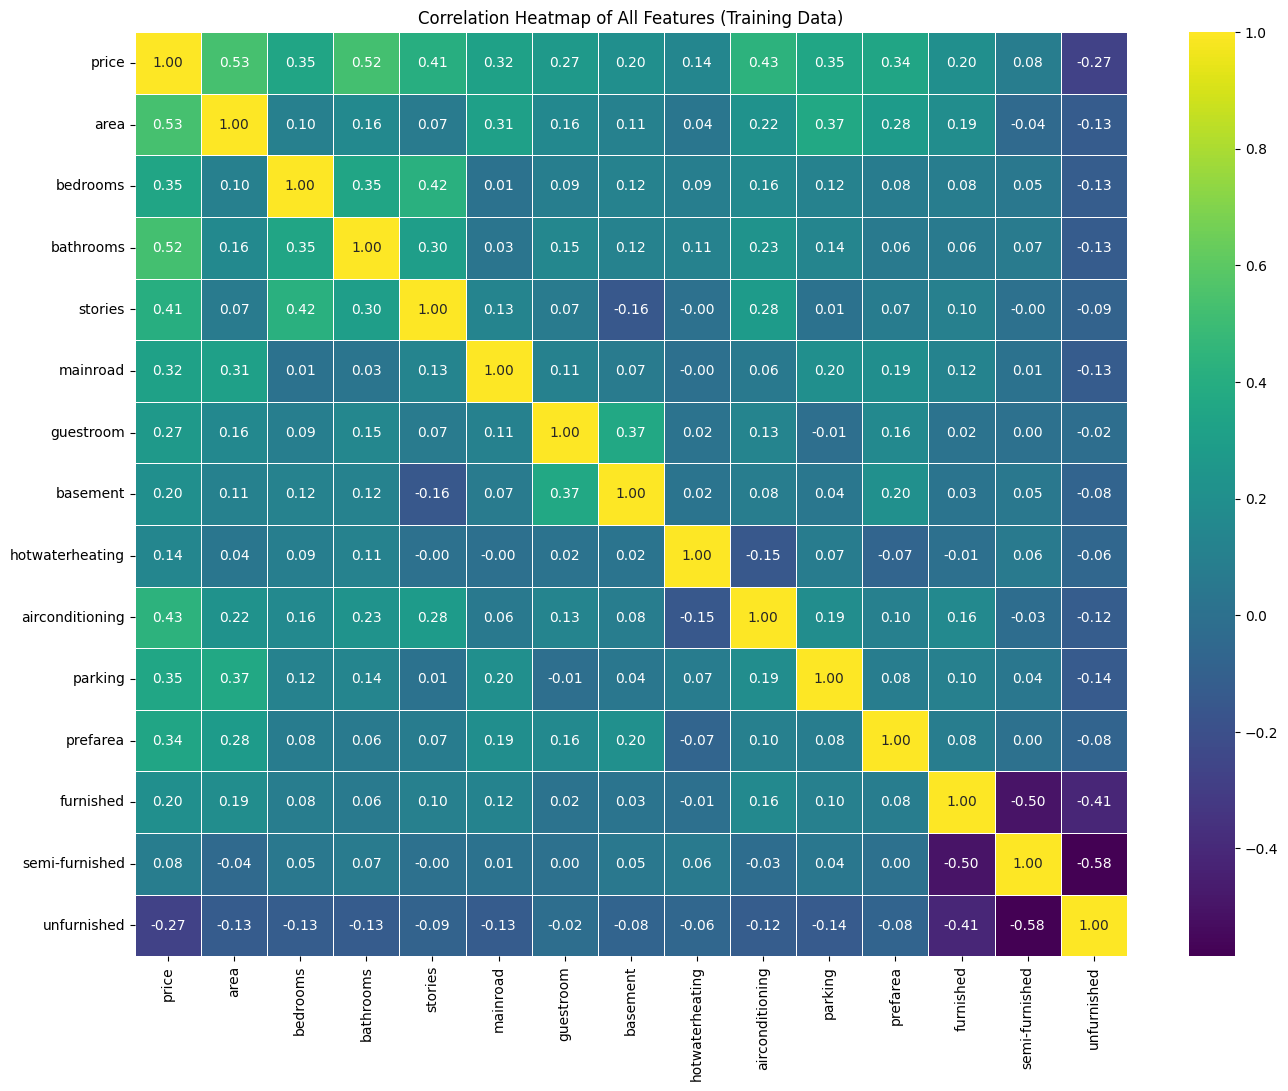

In [20]:
plt.figure(figsize=(16, 12))
sns.heatmap(df_train.corr(), annot=True, cmap='viridis', fmt=".2f", linewidths=.5)
plt.title('Correlation Heatmap of All Features (Training Data)')
plt.show()

# Step4: Scaling the data using normalization or standardization.

# Step5: Build your model
- 5.1 Apply RFE(Recursive Feature Selection) if desired.
- 5.2 Check its OLS(Ordinary Least Square) using statsmodel to check the entire summary and interpretation
- 5.3 Check VIF (Variance Inflation Factor) for all features.

In [21]:
y_train = df_train.pop('price')
X_train = df_train

In [22]:
X_train.head()

,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnished,semi-furnished,unfurnished
359,0.155227,0.4,0.0,0.000000,1,0,0,0,0,0.333333,0,False,False,True
19,0.403379,0.4,0.5,0.333333,1,0,0,0,1,0.333333,1,False,True,False
159,0.115628,0.4,0.5,0.000000,1,1,1,0,1,0.000000,0,True,False,False
35,0.454417,0.4,0.5,1.000000,1,0,0,0,1,0.666667,0,True,False,False
28,0.538015,0.8,0.5,0.333333,1,0,1,1,0,0.666667,0,False,False,True


 # **We only use transform() function with testing data, whenever we use fit_transform() bcz fit_transform() can lead to data leakage of testing data to the model as the fit() function can see the values in the model.**

In [24]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_train_lm = sm.add_constant(X_train)
lr_1 = sm.OLS(y_train, X_train_lm).fit()
lr_1.summary()

/tmp/ipykernel_1630/1398369257.py:5: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  lr_1 = sm.OLS(y_train, X_train_lm).fit()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.681
Model:                            OLS   Adj. R-squared:                  0.670
Method:                 Least Squares   F-statistic:                     60.40
Date:                Thu, 24 Sep 2026   Prob (F-statistic):           8.83e-83
Time:                        05:39:27   Log-Likelihood:                 381.79
No. Observations:                 381   AIC:                            -735.6
Df Residuals:                     367   BIC:                            -680.4
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
===================================================================================
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               0.0075      0.014      0.549      0.584      -0.019       0.034
area                0.2347      0.030      7.795      0.000       0.175       0.294
bedrooms            0.0467      0.037      1.267      0.206      -0.026       0.119
bathrooms           0.1908      0.022      8.679      0.000       0.148       0.234
stories             0.1085      0.019      5.661      0.000       0.071       0.146
mainroad            0.0504      0.014      3.520      0.000       0.022       0.079
guestroom           0.0304      0.014      2.233      0.026       0.004       0.057
basement            0.0216      0.011      1.943      0.053      -0.000       0.043
hotwaterheating     0.0849      0.022      3.934      0.000       0.042       0.127
airconditioning     0.0669      0.011      5.899      0.000       0.045       0.089
parking             0.0607      0.018      3.365      0.001       0.025       0.096
prefarea            0.0594      0.012      5.040      0.000       0.036       0.083
furnished           0.0125      0.009      1.338      0.182      -0.006       0.031
semi-furnished      0.0135      0.008      1.747      0.081      -0.002       0.029
unfurnished        -0.0185      0.008     -2.456      0.014      -0.033      -0.004
==============================================================================
Omnibus:                       93.687   Durbin-Watson:                   2.093
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              304.917
Skew:                           1.091   Prob(JB):                     6.14e-67
Kurtosis:                       6.801   Cond. No.                     3.33e+15
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The smallest eigenvalue is 9.86e-29. This might indicate that there are
strong multicollinearity problems or that the design matrix is singular.
"""

In [30]:
import statsmodels.api as sm

X_train_lm = sm.add_constant(X_train['area'])     # adding intwercept we use the add constant function otherwise the model is supposed to have the best fit line pass through the origin.
lr_1 = sm.OLS(y_train, X_train_lm).fit()          # Ordinary Least Square R2
lr_1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.283
Model:                            OLS   Adj. R-squared:                  0.281
Method:                 Least Squares   F-statistic:                     149.6
Date:                Thu, 24 Sep 2026   Prob (F-statistic):           3.15e-29
Time:                        07:08:57   Log-Likelihood:                 227.23
No. Observations:                 381   AIC:                            -450.5
Df Residuals:                     379   BIC:                            -442.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.1269      0.013      9.853      0.000       0.102       0.152
area           0.4622      0.038     12.232      0.000       0.388       0.536
==============================================================================
Omnibus:                       67.313   Durbin-Watson:                   2.018
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              143.063
Skew:                           0.925   Prob(JB):                     8.59e-32
Kurtosis:                       5.365   Cond. No.                         5.99
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [31]:
lr_1.params

,0
const,0.126894
area,0.462192


In [32]:
import statsmodels.api as sm

X_train_lm = sm.add_constant(X_train[['area', 'bathrooms']])
lr_2 = sm.OLS(y_train, X_train_lm).fit()
lr_2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.480
Model:                            OLS   Adj. R-squared:                  0.477
Method:                 Least Squares   F-statistic:                     174.1
Date:                Thu, 24 Sep 2026   Prob (F-statistic):           2.51e-54
Time:                        07:09:13   Log-Likelihood:                 288.24
No. Observations:                 381   AIC:                            -570.5
Df Residuals:                     378   BIC:                            -558.6
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.1046      0.011      9.384      0.000       0.083       0.127
area           0.3984      0.033     12.192      0.000       0.334       0.463
bathrooms      0.2984      0.025     11.945      0.000       0.249       0.347
==============================================================================
Omnibus:                       62.839   Durbin-Watson:                   2.157
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              168.790
Skew:                           0.784   Prob(JB):                     2.23e-37
Kurtosis:                       5.859   Cond. No.                         6.17
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [33]:
lr_2.params

,0
const,0.104589
area,0.398396
bathrooms,0.298374


In [34]:
import statsmodels.api as sm

X_train_lm = sm.add_constant(X_train)
lr_3 = sm.OLS(y_train, X_train_lm).fit()
lr_3.summary()

/tmp/ipykernel_1630/210313091.py:4: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  lr_3 = sm.OLS(y_train, X_train_lm).fit()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.681
Model:                            OLS   Adj. R-squared:                  0.670
Method:                 Least Squares   F-statistic:                     60.40
Date:                Thu, 24 Sep 2026   Prob (F-statistic):           8.83e-83
Time:                        07:12:53   Log-Likelihood:                 381.79
No. Observations:                 381   AIC:                            -735.6
Df Residuals:                     367   BIC:                            -680.4
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
===================================================================================
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               0.0075      0.014      0.549      0.584      -0.019       0.034
area                0.2347      0.030      7.795      0.000       0.175       0.294
bedrooms            0.0467      0.037      1.267      0.206      -0.026       0.119
bathrooms           0.1908      0.022      8.679      0.000       0.148       0.234
stories             0.1085      0.019      5.661      0.000       0.071       0.146
mainroad            0.0504      0.014      3.520      0.000       0.022       0.079
guestroom           0.0304      0.014      2.233      0.026       0.004       0.057
basement            0.0216      0.011      1.943      0.053      -0.000       0.043
hotwaterheating     0.0849      0.022      3.934      0.000       0.042       0.127
airconditioning     0.0669      0.011      5.899      0.000       0.045       0.089
parking             0.0607      0.018      3.365      0.001       0.025       0.096
prefarea            0.0594      0.012      5.040      0.000       0.036       0.083
furnished           0.0125      0.009      1.338      0.182      -0.006       0.031
semi-furnished      0.0135      0.008      1.747      0.081      -0.002       0.029
unfurnished        -0.0185      0.008     -2.456      0.014      -0.033      -0.004
==============================================================================
Omnibus:                       93.687   Durbin-Watson:                   2.093
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              304.917
Skew:                           1.091   Prob(JB):                     6.14e-67
Kurtosis:                       6.801   Cond. No.                     3.33e+15
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The smallest eigenvalue is 9.86e-29. This might indicate that there are
strong multicollinearity problems or that the design matrix is singular.
"""

In [35]:
lr_3.params

,0
const,0.007503
area,0.234664
bedrooms,0.046735
bathrooms,0.190823
stories,0.108516
mainroad,0.050441
guestroom,0.030428
basement,0.021595
hotwaterheating,0.084863
airconditioning,0.066881


In [38]:
# Statistical Importance of teh variable and VIF (Check Multicollinearity)
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif = pd.DataFrame()
vif['Features'] = X_train.columns
vif['VIF'] = [variance_inflation_factor(X_train.values, i)
              for i in range(X_train.shape[1])]
vif['VIF'] = round(vif['VIF'], 2)
vif = vif.sort_values(by = "VIF", ascending = False)
vif

/tmp/ipykernel_1630/1230720306.py:6: UserWarning: The design matrix is poorly conditioned (condition number=7.87e+15). VIF calculations may be numerically unstable.
  vif['VIF'] = [variance_inflation_factor(X_train.values, i)
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers

,Features,VIF
13,unfurnished,1.000800e+15
12,semi-furnished,1.000800e+15
11,furnished,1.000800e+15
3,stories,1.480000e+00
0,area,1.380000e+00
1,bedrooms,1.370000e+00
6,basement,1.310000e+00
2,bathrooms,1.260000e+00
8,airconditioning,1.250000e+00
9,parking,1.240000e+00


# **Dropping the variable with very high VIF values that is usually greater than 5**

In [23]:
X = X_train.drop(['semi-furnished', 'unfurnished'], axis = 1)

In [24]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [25]:
print(X.dtypes)

area               float64
bedrooms           float64
bathrooms          float64
stories            float64
mainroad             int64
guestroom            int64
basement             int64
hotwaterheating      int64
airconditioning      int64
parking            float64
prefarea             int64
furnished             bool
dtype: object


In [26]:
X_train_lm = sm.add_constant(X.astype(float))
lr_4 = sm.OLS(y_train, X_train_lm).fit()
lr_4.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.674
Model:                            OLS   Adj. R-squared:                  0.664
Method:                 Least Squares   F-statistic:                     63.48
Date:                Tue, 29 Sep 2026   Prob (F-statistic):           6.25e-82
Time:                        14:43:35   Log-Likelihood:                 377.52
No. Observations:                 381   AIC:                            -729.0
Df Residuals:                     368   BIC:                            -677.8
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
===================================================================================
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               0.0007      0.018      0.041      0.968      -0.035       0.036
area                0.2336      0.030      7.683      0.000       0.174       0.293
bedrooms            0.0519      0.037      1.394      0.164      -0.021       0.125
bathrooms           0.1946      0.022      8.782      0.000       0.151       0.238
stories             0.1087      0.019      5.617      0.000       0.071       0.147
mainroad            0.0532      0.014      3.683      0.000       0.025       0.082
guestroom           0.0290      0.014      2.109      0.036       0.002       0.056
basement            0.0233      0.011      2.076      0.039       0.001       0.045
hotwaterheating     0.0886      0.022      4.074      0.000       0.046       0.131
airconditioning     0.0679      0.011      5.936      0.000       0.045       0.090
parking             0.0641      0.018      3.522      0.000       0.028       0.100
prefarea            0.0602      0.012      5.054      0.000       0.037       0.084
furnished           0.0122      0.011      1.106      0.269      -0.009       0.034
==============================================================================
Omnibus:                       86.900   Durbin-Watson:                   2.091
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              282.655
Skew:                           1.009   Prob(JB):                     4.19e-62
Kurtosis:                       6.706   Cond. No.                         14.0
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [27]:
lr_4.params

const              0.000732
area               0.233563
bedrooms           0.051873
bathrooms          0.194647
stories            0.108739
mainroad           0.053173
guestroom          0.028995
basement           0.023275
hotwaterheating    0.088605
airconditioning    0.067933
parking            0.064066
prefarea           0.060178
furnished          0.012181
dtype: float64

In [28]:
# Statistical Importance of teh variable and VIF (Check Multicollinearity)
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = X.astype(float)
vif = pd.DataFrame()
vif['Features'] = X.columns
vif['VIF'] = [variance_inflation_factor(X.values, i)
              for i in range(X.shape[1])]
vif['VIF'] = round(vif['VIF'], 2)
vif = vif.sort_values(by = "VIF", ascending = False)
vif

,Features,VIF
1,bedrooms,6.29
4,mainroad,5.62
0,area,4.73
3,stories,2.68
9,parking,2.11
6,basement,2.01
8,airconditioning,1.78
2,bathrooms,1.65
10,prefarea,1.50
5,guestroom,1.47


- **high p-value and high vif (definitely remove)**
- **high p-value and low vif (terminate them first)**
- **low p-value and high vif (then remove high vif variables)**
- **low p-value and low vif (good features)**

# Step6: Do residual analysis on the training dataset.

C:\Users\ASUS\AppData\Local\Temp\ipykernel_15296\1528359944.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot((y_train - y_train_price), bins = 20)


Text(0.5, 0, 'Errors')

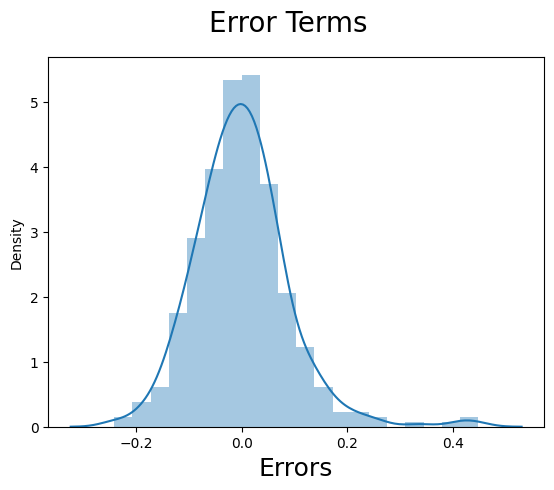

In [29]:
y_train_price = lr_4.predict(X_train_lm)

fig = plt.figure()
sns.distplot((y_train - y_train_price), bins = 20)
fig.suptitle('Error Terms', fontsize = 20)                  # Plot heading
plt.xlabel('Errors', fontsize = 18)                         # X-label

C:\Users\ASUS\AppData\Local\Temp\ipykernel_15296\2188767885.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(y_train, hist=False, label='Actual Price (y_train)', kde_kws={'linewidth': 2})
C:\Users\ASUS\AppData\Local\Temp\ipykernel_15296\2188767885.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad637275

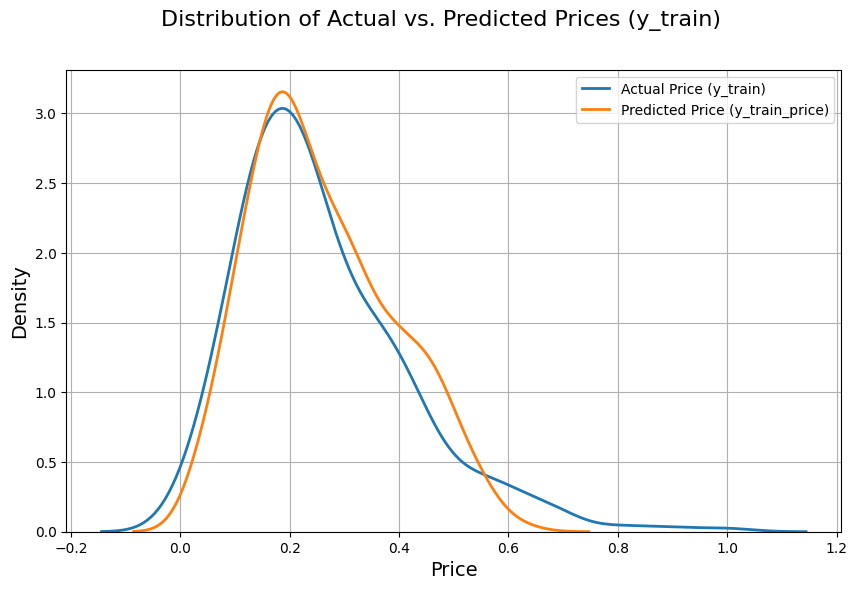

In [30]:
fig = plt.figure(figsize=(10, 6))
sns.distplot(y_train, hist=False, label='Actual Price (y_train)', kde_kws={'linewidth': 2})
sns.distplot(y_train_price, hist=False, label='Predicted Price (y_train_price)', kde_kws={'linewidth': 2})
fig.suptitle('Distribution of Actual vs. Predicted Prices (y_train)', fontsize=16)
plt.xlabel('Price', fontsize=14)
plt.ylabel('Density', fontsize=14)
plt.legend()
plt.grid(True)
plt.show()

# Step7: Making Prediction.
- 7.1 Do the scaling of the test data.
- 7.2 Run the Predict Statement.

In [31]:
num_vars = ['area', 'bedrooms', 'bathrooms', 'stories', 'parking', 'price']
df_test[num_vars] = scaler.transform(df_test[num_vars])
df_test.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnished,semi-furnished,unfurnished
265,0.229697,0.091869,0.4,0.0,0.333333,1,0,0,0,0,0.000000,1,False,True,False
54,0.484848,0.366420,0.4,0.5,0.333333,1,1,0,0,1,0.333333,0,False,True,False
171,0.303030,0.742080,0.4,0.0,0.000000,1,0,0,0,0,0.333333,1,False,True,False
244,0.242424,0.306582,0.4,0.0,0.333333,1,1,1,0,0,0.000000,1,False,True,False
268,0.227879,0.274023,0.6,0.0,0.333333,1,0,0,0,1,0.000000,0,False,True,False


# Step8: Model Evaluation

In [33]:
import pickle

with open("scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

with open("model_params.pkl", "wb") as f:
    pickle.dump(lr_4.params, f)